# Проект: HR-аналитика компании "Работа с заботой"

# Загрузка требуемых для выполнения задач библиотек

In [1]:
!pip install phik -q

In [2]:
!pip install scikit-learn==1.1.3 -q

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statistics import stdev
from phik import phik_matrix
from phik.report import plot_correlation_matrix

from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, make_scorer

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.svm import SVC, SVR

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

# Решение задачи 1

Нам предстоит задача HR-аналитики компании "Работа с заботой". У нас есть данные сотрудников, и мы должны помочь компании предсказывать отток сотрудников.

**Цель исследования:** Построить модель дляпредсказания уровня удовлетворённости на основе предоставленных данных

**Исходные данные:** три таблицы, одна с тренировочной выборкой, в которую также строена таргетная переменная, вторая это тестовая выборка без таргетной переменной и послденяя таблицы с таргетной переменной

# Шаг 1. Загрузка данных

Считаем предоставленные нам данные

In [4]:
X_train = pd.read_csv('/datasets/train_job_satisfaction_rate.csv')
X_test = pd.read_csv('/datasets/test_features.csv')
y_test = pd.read_csv('/datasets/test_target_job_satisfaction_rate.csv')

Проверим корректно ли они считались

In [5]:
print('Размеры таблицы X_train',X_train.shape)
X_train.info()
display(X_train.head(5))

Размеры таблицы X_train (4000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     4000 non-null   int64  
 1   dept                   3994 non-null   object 
 2   level                  3996 non-null   object 
 3   workload               4000 non-null   object 
 4   employment_years       4000 non-null   int64  
 5   last_year_promo        4000 non-null   object 
 6   last_year_violations   4000 non-null   object 
 7   supervisor_evaluation  4000 non-null   int64  
 8   salary                 4000 non-null   int64  
 9   job_satisfaction_rate  4000 non-null   float64
dtypes: float64(1), int64(4), object(5)
memory usage: 312.6+ KB


,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,job_satisfaction_rate
0,155278,sales,junior,medium,2,no,no,1,24000,0.58
1,653870,hr,junior,high,2,no,no,5,38400,0.76
2,184592,sales,junior,low,1,no,no,2,12000,0.11
3,171431,technology,junior,low,4,no,no,2,18000,0.37
4,693419,hr,junior,medium,1,no,no,3,22800,0.20


Сразу можно сказать, что в признаках dept и level есть пропуски. По типам данных все считалось корректно.

In [6]:
print('Размеры таблицы X_test',X_test.shape)
X_test.info()
display(X_test.head(5))

Размеры таблицы X_test (2000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   id                     2000 non-null   int64 
 1   dept                   1998 non-null   object
 2   level                  1999 non-null   object
 3   workload               2000 non-null   object
 4   employment_years       2000 non-null   int64 
 5   last_year_promo        2000 non-null   object
 6   last_year_violations   2000 non-null   object
 7   supervisor_evaluation  2000 non-null   int64 
 8   salary                 2000 non-null   int64 
dtypes: int64(4), object(5)
memory usage: 140.8+ KB


,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary
0,485046,marketing,junior,medium,2,no,no,5,28800
1,686555,hr,junior,medium,1,no,no,4,30000
2,467458,sales,middle,low,5,no,no,4,19200
3,418655,sales,middle,low,6,no,no,4,19200
4,789145,hr,middle,medium,5,no,no,5,40800


Аналогичная ситуация, пропуски в признаках dept и level, по типам данных тут тоже все хорошо

In [7]:
print('Размеры таблицы y_test',y_test.shape)
y_test.info()
display(y_test.head(5))

Размеры таблицы y_test (2000, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     2000 non-null   int64  
 1   job_satisfaction_rate  2000 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 31.4 KB


,id,job_satisfaction_rate
0,130604,0.74
1,825977,0.75
2,418490,0.60
3,555320,0.72
4,826430,0.08


В последней таблице все хорошо, пропусков нет, типы данных соответствуют

По итогу загрузки данных можно сказать, что данные считались корректно, типы данных соответствуют столбцам, единственное неудобство это наличие нескольких пропусков в категориальных столбцах, с ними мы расправимся в следующих разделах

# Шаг 2. Предобработка данных

Пропуски уже были обнаружены на этапе загрузки данных, в данном разделе мы их заполнять не будем, они будут заполнены на этапе создания пайплайна

Посмотрим как дела обстоят с дубликатами

In [8]:
print(X_train.duplicated().sum())
print(X_test.duplicated().sum())
print(y_test.duplicated().sum())

0
0
0


Явных нет, а что насчет неявных?

In [9]:
cat_cols = ['dept',
            'level',
            'workload',
            'last_year_promo',
            'last_year_violations']

print('Проверка на неявные дубликаты в тренировочной выборке')
for column in cat_cols:
    print(X_train[column].value_counts())
    print()

print('Проверка на неявные дубликаты в тестовой выборке')
for column in cat_cols:
    print(X_test[column].value_counts())
    print()

Проверка на неявные дубликаты в тренировочной выборке
sales         1512
technology     866
purchasing     610
marketing      550
hr             456
Name: dept, dtype: int64

junior    1894
middle    1744
sinior     358
Name: level, dtype: int64

medium    2066
low       1200
high       734
Name: workload, dtype: int64

no     3880
yes     120
Name: last_year_promo, dtype: int64

no     3441
yes     559
Name: last_year_violations, dtype: int64

Проверка на неявные дубликаты в тестовой выборке
sales         763
technology    455
marketing     279
purchasing    273
hr            227
                1
Name: dept, dtype: int64

junior    974
middle    854
sinior    171
Name: level, dtype: int64

medium    1043
low        593
high       363
             1
Name: workload, dtype: int64

no     1937
yes      63
Name: last_year_promo, dtype: int64

no     1738
yes     262
Name: last_year_violations, dtype: int64



Неявные дубликаты не обнаружены

По итогу предобработки данных можно сказать, что дубликатов никакого рода не было обнаружено, можно смело приступать к следующему шагу

# Шаг 3. Исследовательский анализ данных

Исследовательский анализ данных будем делать поэтапно, вначале рассмотрим тренировочную выборку. Для начала разобьем данные на количественные и категориальные признаки.

In [10]:
#Список с категориальными признаками уже был создан, смотри ячейки выше
num_cols = ['employment_years',
            'supervisor_evaluation',
            'salary',
            'job_satisfaction_rate']

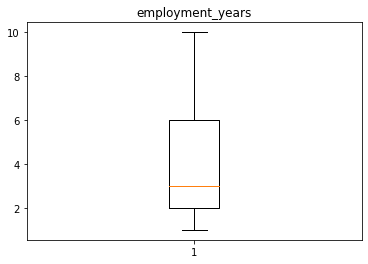

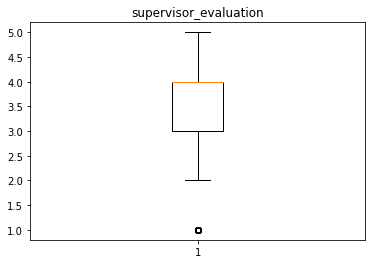

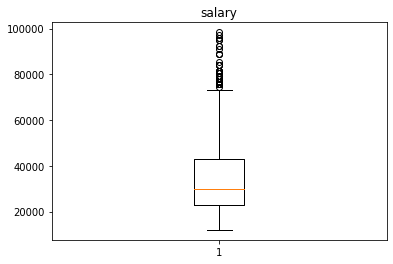

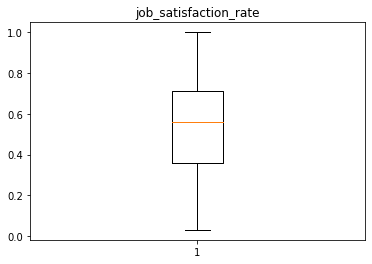

In [11]:
for column in num_cols:
    plt.title(column)
    plt.boxplot(X_train[column])
    plt.show()

Диаграмма размаха показала, что есть значения выбивающиеся за нормаль, но выбросов нет

Также важный момент это то, что некоторые количественные признаки дискретные, а какие то непрерывные, соответственно, для дискретных мы будем строить столбчатую диаграмму, а для непрерывных гистограммы. Для всех диаграмм проведем статистические тесты, для установления типа распределения

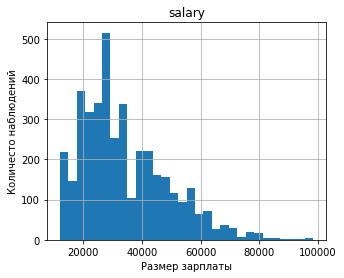

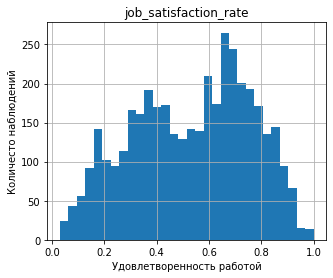

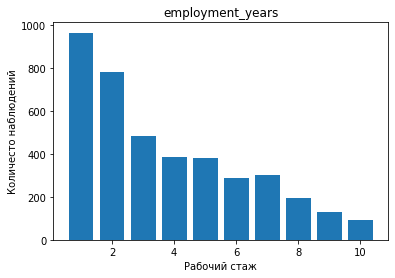

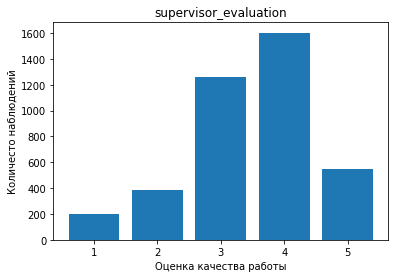

In [12]:
num_interval_cols = ['salary','job_satisfaction_rate']
num_discret_cols = ['employment_years','supervisor_evaluation']

distr = ['norm', 'expon', 'uniform', 'gamma', 'beta']

Labels = {
    'salary' : ['Размер зарплаты', 'Количесто наблюдений'],
    'job_satisfaction_rate' : ['Удовлетворенность работой','Количесто наблюдений'],
    'employment_years' : ['Рабочий стаж','Количесто наблюдений'],
    'supervisor_evaluation' : ['Оценка качества работы','Количесто наблюдений']
}

for column in num_interval_cols:
    plt.title(column)
    X_train[column].hist(bins=30,figsize=(5,4))
    plt.xlabel(Labels[column][0])
    plt.ylabel(Labels[column][1])
    plt.show()
    for d in distr:
        if stats.kstest(X_train[column], 'norm', args=(X_train[column].mean(),stdev(X_train[column])), alternative='two-sided').pvalue>0.05:
            print('распределение отосится к',d,'распределению')
    
for column in num_discret_cols:
    plt.title(column)
    plt.bar(X_train[column].value_counts().index, X_train[column].value_counts().values)
    plt.xlabel(Labels[column][0])
    plt.ylabel(Labels[column][1])
    plt.show()
    for d in distr:
        if stats.kstest(X_train[column], 'norm', args=(X_train[column].mean(),stdev(X_train[column])), alternative='two-sided').pvalue>0.05:
            print('распределение отосится к',d,'распределению')

Ни одно из построенных распределений нельзя причислить к одному конкретному типу

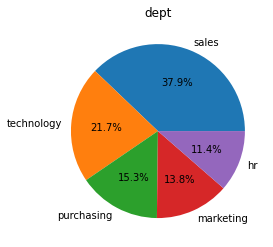

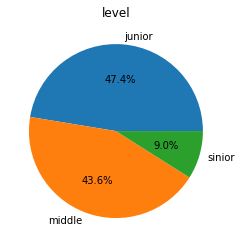

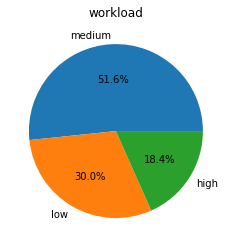

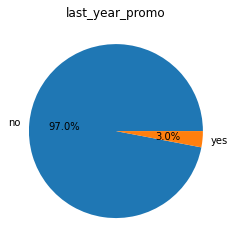

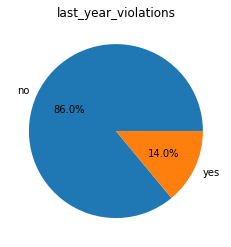

In [13]:
for column in cat_cols:
    plt.pie(X_train[column].value_counts().values, labels=X_train[column].value_counts().index,autopct='%1.1f%%')
    plt.title(column)
    plt.show()

Самый многочисленный отдел в компании это отдел продаж, на втором месте отдел технологий. В плане уровня квалификации, самые в равной большой степени представлены джуны и мидлы, сениоры напротив очень редки. В плане уровня загруженности сотрудника преобладает средняя загруженность. В за последний год никого не повышали почти, только 3 процента сотрудников были повышены. На удивление процент нарушения трудового договора довольно таки велик - 14 процентов.

Перейдем к тестовой выборке

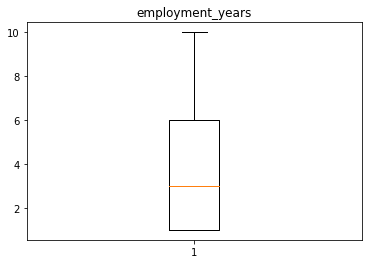

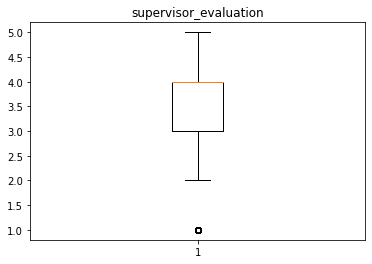

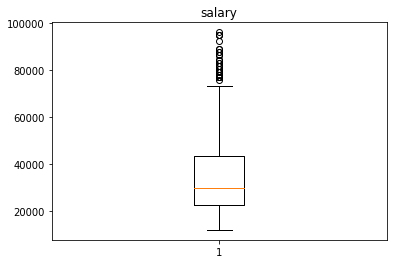

In [14]:
for column in ['employment_years','supervisor_evaluation','salary',]:
    plt.title(column)
    plt.boxplot(X_test[column])
    plt.show()

Выбросов не обнаружено, теперб построим диаграммы

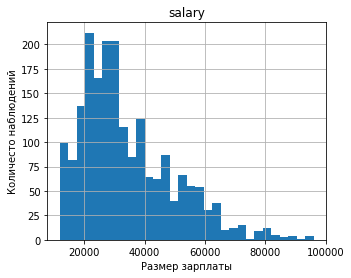

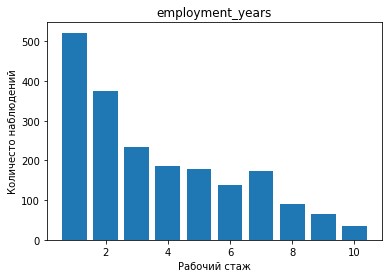

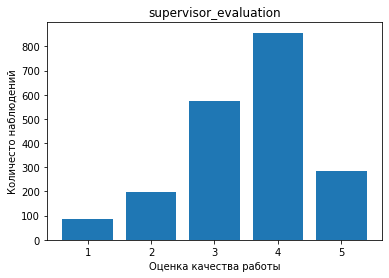

In [15]:
for column in ['salary']:
    plt.title(column)
    X_test[column].hist(bins=30,figsize=(5,4))
    plt.xlabel(Labels[column][0])
    plt.ylabel(Labels[column][1])
    plt.show()
    for d in distr:
        if stats.kstest(X_test[column], 'norm', args=(X_test[column].mean(),stdev(X_test[column])), alternative='two-sided').pvalue>0.05:
            print('распределение отосится к',d,'распределению')
    
for column in num_discret_cols:
    plt.title(column)
    plt.bar(X_test[column].value_counts().index, X_test[column].value_counts().values)
    plt.xlabel(Labels[column][0])
    plt.ylabel(Labels[column][1])
    plt.show()
    for d in distr:
        if stats.kstest(X_test[column], 'norm', args=(X_test[column].mean(),stdev(X_test[column])), alternative='two-sided').pvalue>0.05:
            print('распределение отосится к',d,'распределению')

Та же самая ситуация, не можем отнести ни одно распределение к конкретному одному типу

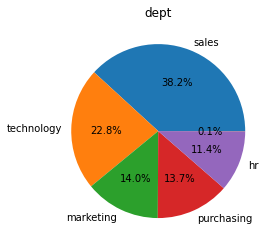

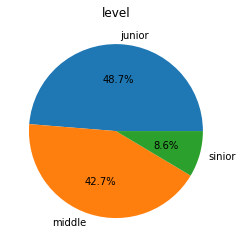

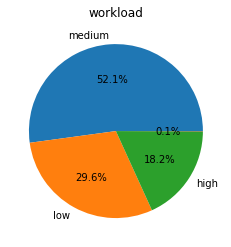

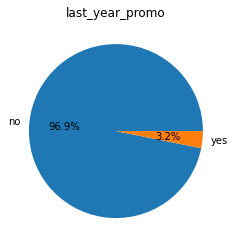

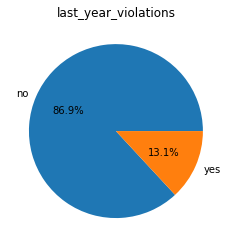

In [16]:
for column in cat_cols:
    plt.pie(X_test[column].value_counts().values, labels=X_test[column].value_counts().index,autopct='%1.1f%%')
    plt.title(column)
    plt.show()

Распределения категориальных признаков в тестовой выборке аналогичны тренировочной, но стоит отметить, что на диаграммы вылезли малопредставленные категории с 0,1 процентом, не пугаемся, это все еще те самые пропуски, которые мы уберем на этапе пайплайна

 Отдельно также важно построить матрицу кореляций для тренировочной выборки

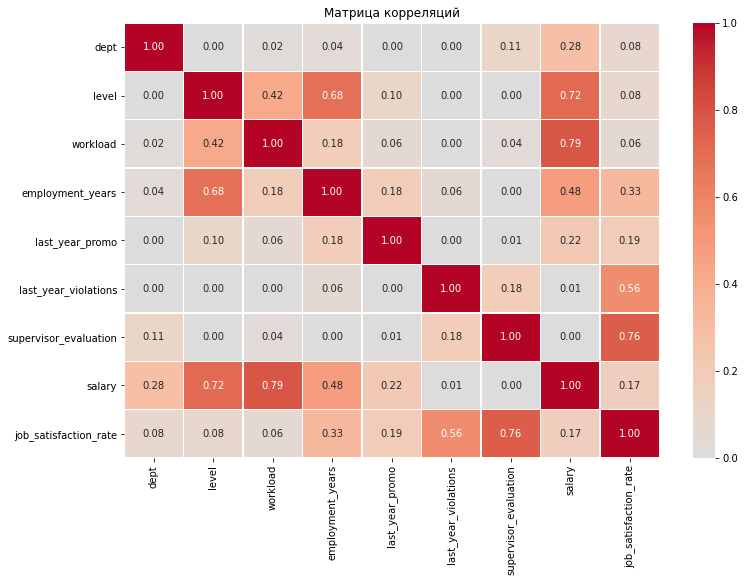

In [17]:
phik_overview = X_train.drop('id',axis=1).phik_matrix(interval_cols=num_interval_cols)

plt.figure(figsize=(12, 8))
sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
plt.title("Матрица корреляций")
plt.show()

Мультиколинеарностей не найдено, теперь построим для тестовой

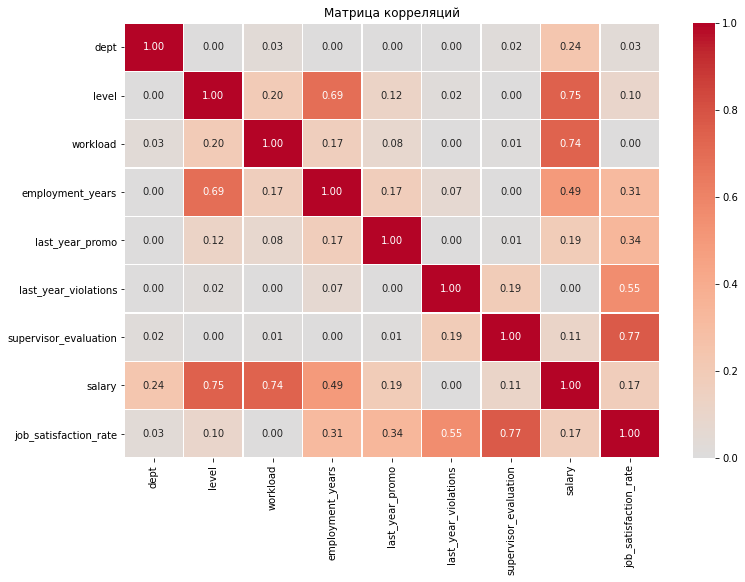

In [18]:
test_for_corr = pd.merge(X_test,y_test,on='id',how='left')
phik_overview = test_for_corr.drop('id',axis=1).phik_matrix(interval_cols=num_interval_cols)

plt.figure(figsize=(12, 8))
sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
plt.title("Матрица корреляций")
plt.show()

Мультиколинеарностей не найдено

По итогу исследовательского анализа данных тренировочной выборки можно сказать, что выбросов в данных не было, распределения количественных признаков нельзя отнести к какому либо типу, а категориальные признаки распределены неравномерно, то же самое можно сказать про тестовую выборку. Также стоит отметить, что при построении круговых диаграмм для тестовой выборки вылезли категории с 0.1 процентом, это пропуски, с которыми мы потом расправимся, на диаграммах тренировочной выборки они не вылезали потому что, она более многочисленная и они не составляли даже 0.1 процент от нее, что делает их невозможными для отображения. Также были построены матрицы корреляций для обеих выборок, которые подтвердили, что нет мультиколинеарностей.

С точки зрения подготовки данных, требуется избавиться от пропусков. Признаки уровня квалификации, загрузки, повышений за прошлый год и нарушения за прошлый год будем кодировать порядковым кодированием, а признак принадлежности сотрудника какому либо отделу будем кодировать бинарным кодом.

# Шаг 4. Подготовка данных

Напишем пайплайн для предобработки данных

In [19]:
RANDOM_STATE = 42

In [20]:
X_train = X_train.drop('id',axis=1)

In [21]:
display(X_train.duplicated().sum())

245

In [22]:
X_train = X_train.drop_duplicates()

In [23]:
display(X_train.duplicated().sum())

0

In [24]:
y_train = X_train['job_satisfaction_rate']
X_train = X_train.drop('job_satisfaction_rate',axis=1)
X_test = pd.merge(X_test,y_test,on='id',how='left')
y_test = X_test['job_satisfaction_rate']
X_test2 = X_test.drop('job_satisfaction_rate',axis=1) 
#сохраняем для второй задачи, чтобы не обрабатывать данные заново и чтобы был столбец с id для соединения
X_test = X_test.drop(['job_satisfaction_rate','id'],axis=1)

In [25]:
ohe_columns = ['dept']
ord_columns = ['level','workload','last_year_promo','last_year_violations']
num_columns = ['salary','employment_years','supervisor_evaluation']

In [26]:
ohe_pipe = Pipeline(
    [('SimpleImputer_ohe', SimpleImputer(missing_values=np.nan,strategy='most_frequent')),
     ('ohe', OneHotEncoder(drop='first',handle_unknown='ignore',sparse=False))
    ]
)

In [27]:
ord_pipe = Pipeline(
    [('SimpleImputer_before_ohe', SimpleImputer(missing_values=np.nan,strategy='most_frequent')),
     ('ord', OrdinalEncoder(
         categories=[
             ['junior','middle','sinior'],
             ['low','medium','high'],
             ['no','yes'],
             ['no','yes']],handle_unknown='use_encoded_value',unknown_value=np.nan)),
     ('SimpleImputer_after_ohe', SimpleImputer(missing_values=np.nan,strategy='most_frequent'))
    ]
)

In [28]:
data_preprocessor = ColumnTransformer(
    [('ohe', ohe_pipe, ohe_columns),
     ('ord', ord_pipe, ord_columns),
     ('num', StandardScaler(), num_columns)
    ], 
    remainder='passthrough'   
)

In [29]:
X_train_new = data_preprocessor.fit_transform(X_train)
X_test_new = data_preprocessor.transform(X_test)
feature_names = data_preprocessor.get_feature_names_out()
X_train_new = pd.DataFrame(X_train_new,columns=feature_names)
X_test_new = pd.DataFrame(X_test_new,columns=feature_names)

/opt/conda/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:188: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# Шаг 5. Обучение моделей

Напишем пайплайн для модели

In [30]:
model_pipe = Pipeline([
    ('models', DecisionTreeRegressor(random_state=RANDOM_STATE))
])

param_grid = [
    {
        'models': [SVR(C=50)],
        'models__kernel': ['linear','rbf'],
    },
    
    {
        'models': [LinearRegression()],
        'models__fit_intercept': [True, False],
        'models__positive': [True, False],
    },

    {
        'models': [DecisionTreeRegressor(random_state=RANDOM_STATE)],
        'models__max_depth': range(2,5),
        'models__max_features': range(2,5),
    }
]

До того как мы начнем подбор модели и параметров для нее, следует написать фунцию для нашей собственной метрики SMAPE(symmetric mean absolute percentage error, «симметричное среднее абсолютное процентное отклонение»)

In [31]:
def SMAPE(y_test,y_pred):
    y_test = np.array(y_test)
    y_pred = np.array(y_pred)
    return np.mean(2.0 * np.abs(y_pred - y_test) / (np.abs(y_pred) + np.abs(y_test))) * 100
smape = make_scorer(SMAPE, greater_is_better=False)

In [32]:
g_search = GridSearchCV(model_pipe,
                      param_grid,
                      cv=5,
                      scoring=smape,
                      n_jobs=-1)

g_search.fit(X_train_new,y_train)
print('Лучшая модель')
print()
print(g_search.best_params_)
print()
print ('Метрика лучшей модели', abs(g_search.best_score_))

preds = g_search.predict(X_test_new)
model = g_search.best_estimator_

Лучшая модель

{'models': SVR(C=50), 'models__kernel': 'rbf'}

Метрика лучшей модели 15.599335441193086


In [33]:
print('Значение метрики на тестовой выборке',abs(smape(model,X_test_new,y_test)))

Значение метрики на тестовой выборке 13.966848041341843


# Шаг 6. Промежуточные выводы

Лучше всего справилась модель SVR с ядром rbf, это произошло, потому что во всей таблице присутствует дисбаланс классов в категориальных признаках

# Решение задачи 2

Теперь Требуется построить еще одну модель, на этот раз, которая будет предсказывать само увольнение сотрудника

**Цель исследования:** построить модель, которая сможет на основе данных предсказать, что сотрудник уволится из компании

**Исходные данные:** нам даны еще две таблицы - новые треннировочные данные(без увольнения и без удовлетворённости) и новая таблица с таргетной перемнной для тестовой выборки, сама тестовая выборка та же, что и была

# Шаг 1. Загрузка данных

Для начала считаем новые данные

In [34]:
X_train2 = pd.read_csv('/datasets/train_quit.csv')
y_test2 = pd.read_csv('/datasets/test_target_quit.csv')

In [35]:
print('Размеры таблицы X_train2',X_train2.shape)
X_train2.info()
display(X_train2.head(5))

Размеры таблицы X_train2 (4000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   id                     4000 non-null   int64 
 1   dept                   4000 non-null   object
 2   level                  4000 non-null   object
 3   workload               4000 non-null   object
 4   employment_years       4000 non-null   int64 
 5   last_year_promo        4000 non-null   object
 6   last_year_violations   4000 non-null   object
 7   supervisor_evaluation  4000 non-null   int64 
 8   salary                 4000 non-null   int64 
 9   quit                   4000 non-null   object
dtypes: int64(4), object(6)
memory usage: 312.6+ KB


,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,quit
0,723290,sales,middle,high,2,no,no,4,54000,no
1,814010,sales,junior,medium,2,no,no,4,27600,no
2,155091,purchasing,middle,medium,5,no,no,1,37200,no
3,257132,sales,junior,medium,2,no,yes,3,24000,yes
4,910140,marketing,junior,medium,2,no,no,5,25200,no


In [36]:
print('Размеры таблицы y_test2',y_test2.shape)
y_test2.info()
display(y_test2.head(5))

Размеры таблицы y_test2 (2000, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   quit    2000 non-null   object
dtypes: int64(1), object(1)
memory usage: 31.4+ KB


,id,quit
0,999029,yes
1,372846,no
2,726767,no
3,490105,no
4,416898,yes


Данные считались корректно, пропусков нет, типы данных соответствуют столбцам

# Шаг 2. Предобработка данных

Проверим данные на явные дубликаты

In [37]:
print(X_train2.duplicated().sum())
print(y_test2.duplicated().sum())

0
0


Явные дубликаты не найдены, посмотрим, что там с явными

In [38]:
cat_cols = ['dept',
            'level',
            'workload',
            'last_year_promo',
            'last_year_violations',
            'quit']
print('Проверка на неявные дубликаты в тренировочной выборке')
for column in cat_cols:
    print(X_train2[column].value_counts())
    print()

Проверка на неявные дубликаты в тренировочной выборке
sales         1438
technology     928
purchasing     588
marketing      582
hr             464
Name: dept, dtype: int64

junior    1949
middle    1694
sinior     357
Name: level, dtype: int64

medium    2118
low       1208
high       674
Name: workload, dtype: int64

no     3887
yes     113
Name: last_year_promo, dtype: int64

no     3455
yes     545
Name: last_year_violations, dtype: int64

no     2872
yes    1128
Name: quit, dtype: int64



Неявных дубликатов в новых данных не было найдено

# Шаг 3. Исследовательский анализ данных

Из новых данных у нас новая тренировочная выборка

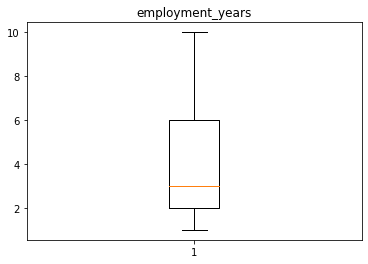

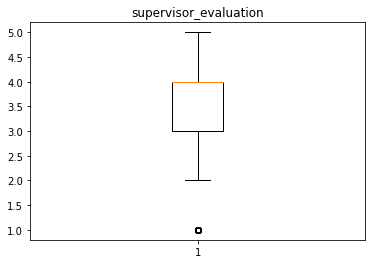

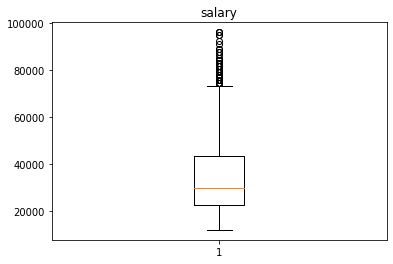

In [39]:
for column in ['employment_years','supervisor_evaluation','salary',]:
    plt.title(column)
    plt.boxplot(X_train2[column])
    plt.show()

Диаграмма размаха показала, что выбросов нет, теперь построим гистограммы для количественных признаков

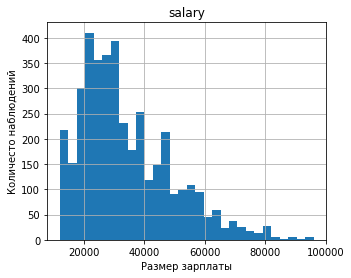

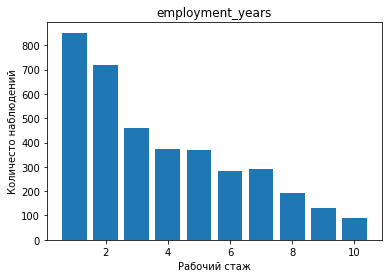

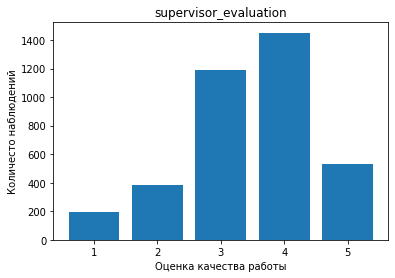

In [40]:
num_interval_cols = ['salary']
num_discret_cols = ['employment_years','supervisor_evaluation']
for column in num_interval_cols:
    plt.title(column)
    X_train2[column].hist(bins=30,figsize=(5,4))
    plt.xlabel(Labels[column][0])
    plt.ylabel(Labels[column][1])
    plt.show()
    for d in distr:
        if stats.kstest(X_train2[column], 'norm', args=(X_train2[column].mean(),stdev(X_train2[column])), alternative='two-sided').pvalue>0.05:
            print('распределение отосится к',d,'распределению')
    
for column in num_discret_cols:
    plt.title(column)
    plt.bar(X_train[column].value_counts().index, X_train[column].value_counts().values)
    plt.xlabel(Labels[column][0])
    plt.ylabel(Labels[column][1])
    plt.show()
    for d in distr:
        if stats.kstest(X_train2[column], 'norm', args=(X_train2[column].mean(),stdev(X_train2[column])), alternative='two-sided').pvalue>0.05:
            print('распределение отосится к',d,'распределению')

Опять таки, мы не можем отнести ни одно распределение к одному конкретному типу

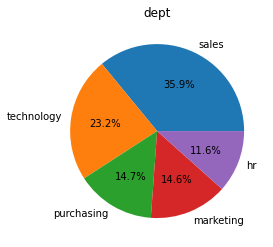

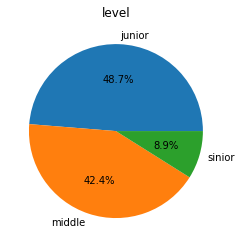

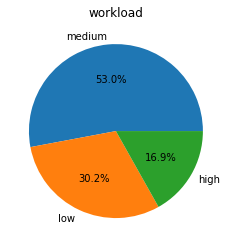

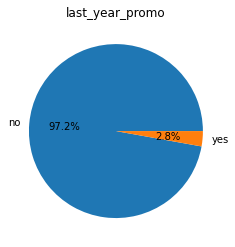

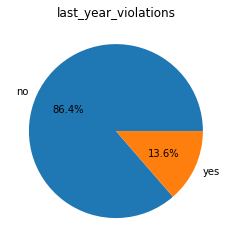

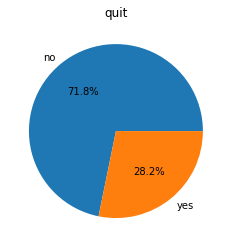

In [41]:
for column in cat_cols:
    plt.pie(X_train2[column].value_counts().values, labels=X_train2[column].value_counts().index,autopct='%1.1f%%')
    plt.title(column)
    plt.show()

По признакам, который уже были раньше все идентично первой задаче, но теперь у нас новый признак с таргетной переменной, ухода сотрудника из компании, его распределение неравномерно, 28 процентов сотрудников ушли из компании, остальные остались

Составим портрет уволившегося сотрудника

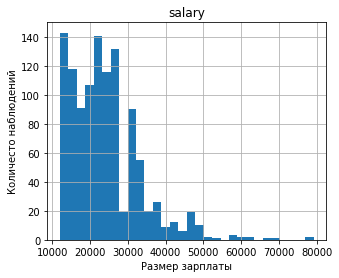

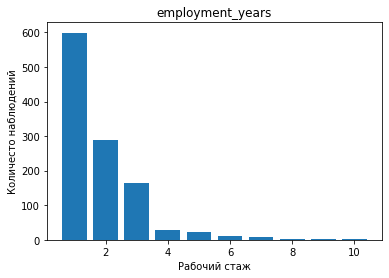

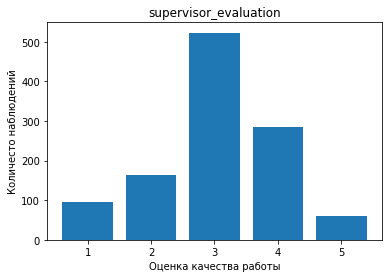

In [42]:
for column in num_interval_cols:
    plt.title(column)
    X_train2[X_train2['quit']=='yes'][column].hist(bins=30,figsize=(5,4))
    plt.xlabel(Labels[column][0])
    plt.ylabel(Labels[column][1])
    plt.show()
    for d in distr:
        if stats.kstest(X_train2[X_train2['quit']=='yes'][column], 'norm', args=(X_train2[X_train2['quit']=='yes'][column].mean(),stdev(X_train2[X_train2['quit']=='yes'][column])), alternative='two-sided').pvalue>0.05:
            print('распределение отосится к',d,'распределению')
    
for column in num_discret_cols:
    plt.title(column)
    plt.bar(X_train2[X_train2['quit']=='yes'][column].value_counts().index, X_train2[X_train2['quit']=='yes'][column].value_counts().values)
    plt.xlabel(Labels[column][0])
    plt.ylabel(Labels[column][1])
    plt.show()
    for d in distr:
        if stats.kstest(X_train2[X_train2['quit']=='yes'][column], 'norm', args=(X_train2[X_train2['quit']=='yes'][column].mean(),stdev(X_train2[X_train2['quit']=='yes'][column])), alternative='two-sided').pvalue>0.05:
            print('распределение отосится к',d,'распределению')

Агааааааа, по количественным признакам видно, что уволившиеся люди получали меньшую зарплату, имели маленький стаж(люди с большим стажом редко увольняются) и имели оценку среднюю 3, а не 4, ниже представлены доли вероятности того, что уволившийся сотрудник имеет ту или иную оценку или стаж работы, также посчитаем точную среднюю величину зарплаты

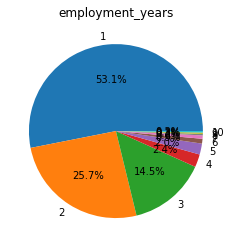

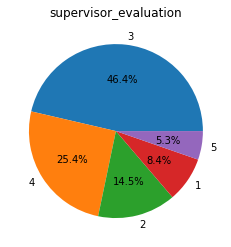

In [43]:
plt.pie(X_train2[X_train2['quit']=='yes']['employment_years'].value_counts().values, labels=X_train2[X_train2['quit']=='yes']['employment_years'].value_counts().index,autopct='%1.1f%%')
plt.title('employment_years')
plt.show()

plt.pie(X_train2[X_train2['quit']=='yes']['supervisor_evaluation'].value_counts().values, labels=X_train2[X_train2['quit']=='yes']['supervisor_evaluation'].value_counts().index,autopct='%1.1f%%')
plt.title('supervisor_evaluation')
plt.show()

Видно, что подавляющее большинство имеет оценку 3 и стаж 1 год

In [44]:
print('Средняя зарплата, которую получает уволившийся сотрудник ', X_train2[X_train2['quit']=='yes']['salary'].mean())
print('Средняя зарплата, которую получает не уволившийся сотрудник ', X_train2[X_train2['quit']=='no']['salary'].mean())

Средняя зарплата, которую получает уволившийся сотрудник  23885.106382978724
Средняя зарплата, которую получает не уволившийся сотрудник  37702.22841225627


Наблюдаем сильную разницу

Теперь поглядим на категориальные признаки

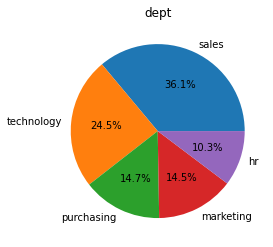

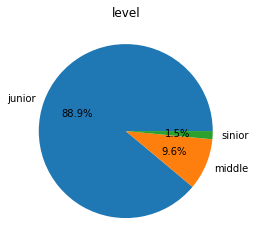

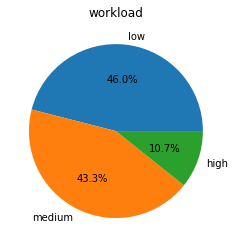

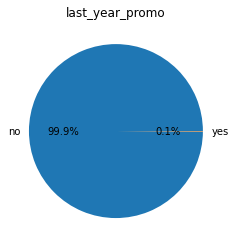

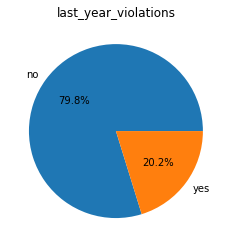

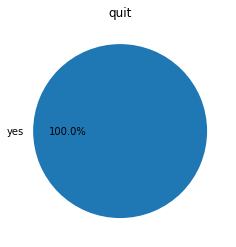

In [45]:
for column in cat_cols:
    plt.pie(X_train2[X_train2['quit']=='yes'][column].value_counts().values, labels=X_train2[X_train2['quit']=='yes'][column].value_counts().index,autopct='%1.1f%%')
    plt.title(column)
    plt.show()

По отделам все примерно так же, но больше нарушений трудового договора(на 7 процентов), вреди уволившихся, почти никого не повышали, намного меньше синиоров и мидлов

Посмотрим как влияет удовлетворённость работой на увольнение

In [46]:
all_test = X_test2.join(y_test,how='left')
all_test = pd.merge(all_test,y_test2,on='id',how='left')

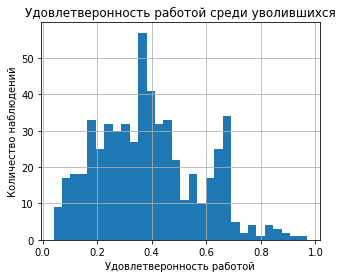

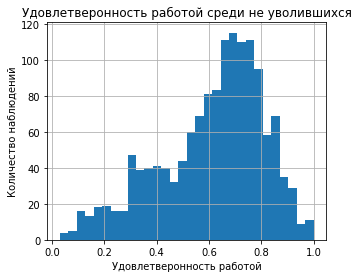

In [47]:
all_test[all_test['quit']=='yes']['job_satisfaction_rate'].hist(bins=30,figsize=(5,4))
plt.title('Удовлетверонность работой среди уволившихся')
plt.xlabel('Удовлетверонность работой')
plt.ylabel('Количество наблюдений')
plt.show()

all_test[all_test['quit']=='no']['job_satisfaction_rate'].hist(bins=30,figsize=(5,4))
plt.title('Удовлетверонность работой среди не уволившихся')
plt.xlabel('Удовлетверонность работой')
plt.ylabel('Количество наблюдений')
plt.show()

Удоавлетворенность значительно меньше среди уволившихся

# Шаг 4. Добавление новго входного признака

Мы выяснили, что статистика увольнений и удовлетворенности работой связаны между собой, давайте использвуем обученную в предыдущей задаче модель, чтобы добавить новый входной признак

In [48]:
preds = pd.DataFrame(preds,columns=['job_satisfaction_rate'])
X_test2 = X_test2.join(preds,how='left')
y_test2 = pd.merge(X_test2,y_test2,on='id',how='left')['quit']

In [49]:
y_train2 = X_train2['quit']
X_train2_new = data_preprocessor.transform(X_train2.drop(['id','quit'],axis=1))
preds_train2 = model.predict(X_train2_new)
preds_train2 = pd.DataFrame(preds_train2,columns=['job_satisfaction_rate'])
X_train2 = X_train2.join(preds_train2,how='left')
all_train2 = X_train2
X_train2 = X_train2.drop('quit',axis=1)

/opt/conda/lib/python3.9/site-packages/sklearn/base.py:450: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(


Новый признак добавлен в таблицы, давайте проверим создал ли он мультиколлинеарности

/opt/conda/lib/python3.9/site-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable job_satisfaction_rate is large: 2455. Are you sure this is not an interval variable? Analysis for pairs of variables including job_satisfaction_rate can be slow.
  warnings.warn(


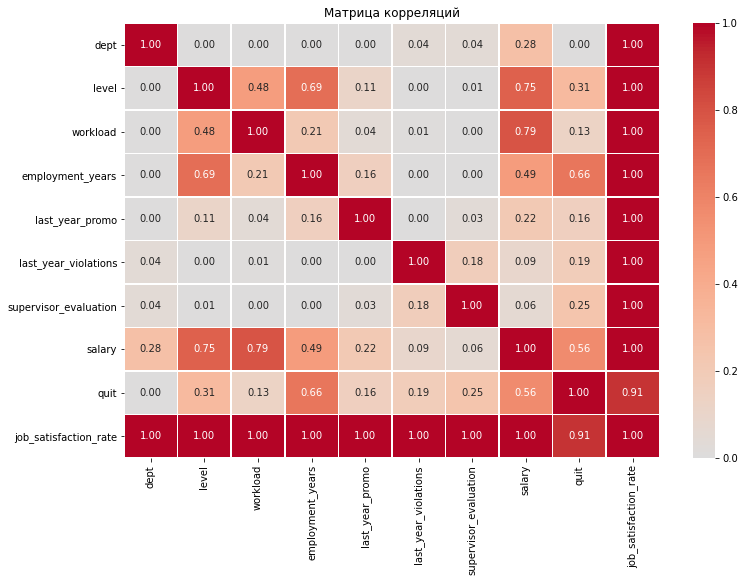

In [50]:
phik_overview = all_train2.drop('id',axis=1).phik_matrix(interval_cols=num_interval_cols)

plt.figure(figsize=(12, 8))
sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
plt.title("Матрица корреляций")
plt.show()

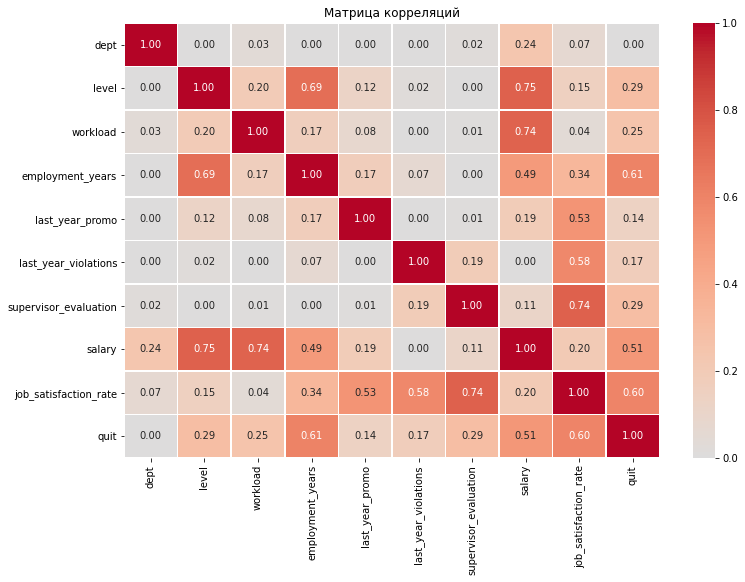

In [51]:
phik_overview = all_test.drop('id',axis=1).phik_matrix(interval_cols=num_interval_cols)

plt.figure(figsize=(12, 8))
sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
plt.title("Матрица корреляций")
plt.show()

На тренировочной выборке, нарушение трудового договора имело мультиколлинеарность, убираем ее

In [52]:
X_train2 = X_train2.drop('last_year_violations',axis=1)
X_test2 = X_test2.drop('last_year_violations',axis=1)

# Шаг 5. Подготовка данных

Новый пайплайн писать не надо для обработки, поэтому напомним с какими столбцами мы работаем, при этом добавим в обработку еще столбец с удовлетворённостью работой

In [53]:
ohe_columns = ['dept']
ord_columns = ['level','workload','last_year_promo']
num_columns = ['salary','employment_years','supervisor_evaluation','job_satisfaction_rate']

In [54]:
ord_pipe = Pipeline(
    [('SimpleImputer_before_ohe', SimpleImputer(missing_values=np.nan,strategy='most_frequent')),
     ('ord', OrdinalEncoder(
         categories=[
             ['junior','middle','sinior'],
             ['low','medium','high'],
             ['no','yes']],handle_unknown='use_encoded_value',unknown_value=np.nan)),
     ('SimpleImputer_after_ohe', SimpleImputer(missing_values=np.nan,strategy='most_frequent'))
    ]
)

In [55]:
data_preprocessor = ColumnTransformer(
    [('ohe', ohe_pipe, ohe_columns),
     ('ord', ord_pipe, ord_columns),
     ('num', StandardScaler(), num_columns)
    ], 
    remainder='passthrough'   
)

Теперь применим обработчик данных к нашим таблицам

In [56]:
X_train2_new = data_preprocessor.fit_transform(X_train2.drop('id',axis=1))
X_test2_new = data_preprocessor.transform(X_test2.drop('id',axis=1))

/opt/conda/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:188: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [57]:
feature_names2 = data_preprocessor.get_feature_names_out()
X_train2_new = pd.DataFrame(X_train2_new,columns=feature_names2)
X_test2_new = pd.DataFrame(X_test2_new,columns=feature_names2)

In [58]:
le = LabelEncoder()
y_train2_new = le.fit_transform(y_train2)
y_test2_new = le.fit_transform(y_test2)

# Шаг 6. Обучение модели

Напишем пайплайн для модели и параметры для подбора GridSearch

In [59]:
model_pipe2 = Pipeline([
    ('models', DecisionTreeClassifier(random_state=RANDOM_STATE))
])

param_grid2 = [
    {
        'models': [SVC(random_state=RANDOM_STATE,probability=True,C=50)],
        'models__kernel': ['linear','poly','rbf','sigmoid'],
    },

    {
        'models': [DecisionTreeClassifier(random_state=RANDOM_STATE)],
        'models__max_depth': range(2,5),
        'models__max_features': range(2,5),
    },
     
    {
        'models': [KNeighborsClassifier()],
        'models__n_neighbors': range(2,5),  
    },

    {
        'models': [LogisticRegression(
            random_state=RANDOM_STATE, 
            solver='liblinear', 
            penalty='l1')],
        'models__C': range(1,5),
    }
]

In [60]:
g_search2 = GridSearchCV(model_pipe2, param_grid2,cv=5,scoring='roc_auc',n_jobs=-1)
g_search2.fit(X_train2_new,y_train2_new)

print('Лучшая модель')
print()
print(g_search2.best_params_)
print()
print ('Метрика лучшей модели', g_search2.best_score_)

preds2 = g_search2.predict_proba(X_test2_new)[:,1]
model2 = g_search2.best_estimator_

Лучшая модель

{'models': SVC(C=50, kernel='poly', probability=True, random_state=42), 'models__kernel': 'poly'}

Метрика лучшей модели 0.9265780905339422


In [61]:
print('Значение метрики на тестовой выборке',roc_auc_score(y_test2_new,preds2))

Значение метрики на тестовой выборке 0.9224056184436673


Лучше всего показала модель SVC с ядром poly

# Итоговый вывод

Вначале мы приступили к первой задаче, которая распылилась на несколько подзадач

Мы загрузили данные и базово ознакомились с ними, считались данные корректно, типы данных соответствуют, но было найдено маленькое количество пропусков

Далее требовалось осуществить предобработку данных, здесь мы проверили данные на дубликаты, в таблицах не оказалось никакого рода дубликатов, поэтому мы приступили к исследовательскому анализу данных

На данном этапе мы построили диаграммы размаха и диаграммы распределений для количественных признаков, сами распределения не получилось отнести ни к одному типу распределений, также были построены круовые диаграммы для категориальных признаков, где были сделаны выводы, что среди отделов самыми многочисленными были отделы продаж и технологий, среди уровней квалификации самыми многочисленными являются мидлы и джуны, сениоры составляют всего лишь 9 процентов, по загрузке работы большинство сотрудников оценивают свою загрузку как среднюю, сотрудников в компании почти не повышали за последний год(всего 3 процента сотрудников были повышены) и всего 14 процентов сотрудников нарушили трудовой договор. Те же диаграммы были построены и для тестовой выборке, где за исключением маленьких отличий сами распределения имеют идентичный характер тем, что были на тренировочной

Далее была выполнена подготовка данных к обучению - был написан пайплайн для обработки данных и применили его к нашим данным

Затем идет этап обучения модели на котором мы написали пайплайн с моделью и переменную с параметрами для него, чтобы далее передать его в GridSearch, для подбора гиперпараметров, нашу модель будем оценивать мерикой SMAPE, которую в этом пункте мы также написали как функцию. По итогу после подбора гиперпараметров лучше всего себя показала модель DecisionTreeRegressor с параметрами max_depth=4, max_features=2

Приступаем ко второй задаче, в ней нам передали новую тренировочную выборку и таргетную переменную - увольнение сотрудника

Все снова начинается с загрузки данных, где мы считали данные и аналогично первой задаче, все типы соответсвовали столбцам, и на этот раз все обошлост даже без пропусков

Далее шел этап предобработки данных, на котором мы проверили наличие дубликатов и убедились, что в таблицах нет явных и неявных дубликатов

Провели исследовательский анализ данных для новой тренировочной выборки, где распределения получились аналогичными первой задаче, также мы проанализировали как меняются распределения, если взять только уволившихся работников, мы увидели, что уволившиеся получают меньшую зарплату, имеют меньший стаж и оценку от специалиста, также они имеют меньший уровень квалификации, меньшее количество повышений за прошлый год и больше нарушают трудовой договор. Также мы посмотрели как влияет удовлетверноть работой в компании на уход сотрудников и увидели, что уволившиеся люди были менее удовлетворены работой в компании

После подтверждения влияния удовлетворенности на таргетную переменную с помощью результатов выполнения первой задачи мы добавили в данные новый входной признак с удовлетворенностью

На основе написанного в первой задаче, мы, добавив в обработку новый признак с удовлетворённостью, подготовили наши данные к обучению модели

На этапе обучения модели мы написали новый пайплайн и параметры для подбора модели. В данном случае было принято решение пользоваться метрикой roc_auc_score. Лучшие результаты показала SVC модель с ядром в виде полинома

Основным выводом будет мотивация персонала к развитию своей квалификации и выдаче лучших результатов, чтобы было меньше неудовлетворённости сотрудников, а соответственно меньше увольнений и меньше текучка кадров